In [ ]:
# Choose python environment. If doesn't work use this --->>   
# (1) python -m venv .venv 
# (2) .venv\Scripts\Activate.ps1

In [1]:
# Set-up/ intall packages.
%pip install "kagglehub[pandas-datasets]" pandas numpy matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# Import installed packages/ libraries into environment?
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub as kh
import zipfile
from pathlib import Path

In [3]:
# Set-up folders --- data and figures --- relative paths to enable the notebook to work on any computer.

DATA_DIR = Path("data")      # raw and clean CSV files go here
FIG_DIR = Path("figures")    # exported plots go here

DATA_DIR.mkdir(exist_ok=True)  # create the folder if it does not exist yet
FIG_DIR.mkdir(exist_ok=True)

In [4]:
# pandas display options 
pd.set_option("display.max_columns", 50)                 # show every column, do not hide them with "..."
pd.set_option("display.float_format", "{:,.2f}".format)  # 1234567.891 -> 1,234,567.89

# plot style 
sns.set_theme(style="whitegrid", context="notebook")  # clean background with a light grid
plt.rcParams["figure.figsize"] = (10, 5)              # default size of every figure (width, height) in inches

# Seed for anything random (sampling): the same seed always gives the same "random" result,
# so everybody in class sees exactly the same numbers.
RANDOM_STATE = 42

In [6]:
# "save_fig()" exports plots as .png 
# Creating a function to call when we need to save a figure (plot during analysis) onto the computer.

def save_fig(name):
    # Save the current figure as a PNG inside FIG_DIR.
    # dpi = dots per inch (resolution). bbox_inches="tight" trims empty white borders.
    path = FIG_DIR / f"{name}.png"
    plt.savefig(path, dpi=150, bbox_inches="tight")
    print(f"Figure saved to {path}")

In [7]:
# Import csv file from data folder.
df = pd.read_csv(
    DATA_DIR / "global_city_col_qol_index.csv"
)

# print info of imported csv data --- check
print(f"Loaded {df.shape[0]:,} rows and {df.shape[1]} columns")

Loaded 296 rows and 26 columns


In [8]:
# The first 5 rows.
df.head()

,city_id,city,country,region,subregion,development_tier,population_millions,currency_code,survey_date,cost_of_living_index,rent_index,groceries_index,restaurant_price_index,local_purchasing_power_index,avg_monthly_net_salary_usd,housing_price_to_income_ratio,health_care_index,safety_index,pollution_index,traffic_commute_index,climate_index,internet_speed_mbps,quality_of_life_index,qol_category,data_source_pattern,analyst_note
0,112,Abidjan,Cote d'Ivoire,Africa,Western Africa,4,4.89,XOF,2023-06-15,43.29,24.06,43.18,46.49,38.45,"1,650.87",18.48,29.59,49.52,86.13,61.74,85.79,38.10,42.92,Medium,Synthetic-Numbeo-pattern,NaN
1,112,Abidjan,Cote d'Ivoire,Africa,Western Africa,4,4.89,XOF,2024-06-15,51.53,26.11,47.59,46.68,43.25,"1,826.78",20.84,22.86,49.85,86.33,63.21,63.07,47.30,32.57,Low,Synthetic-EIU-pattern,New infrastructure projects may improve traffi...
2,76,Abu Dhabi,United Arab Emirates,Asia,Western Asia,1,3.22,AED,2023-06-15,100.39,61.19,86.04,64.62,111.37,"6,040.30",8.82,96.34,94.67,38.15,32.22,83.63,168.40,82.84,Very High,Synthetic-EIU-pattern,NaN
3,76,Abu Dhabi,United Arab Emirates,Asia,Western Asia,1,3.22,AED,2024-06-15,95.65,78.33,98.88,84.45,109.32,"6,363.54",10.11,89.47,56.12,28.94,29.20,31.57,NaN,59.92,High,Synthetic-Mercer-pattern,NaN
4,99,Abuja,Nigeria,Africa,Western Africa,4,2.64,NGN,2023-06-15,46.82,32.79,29.90,39.25,49.86,"2,186.81",18.82,38.37,47.52,78.13,65.04,58.49,81.90,38.86,Medium,Synthetic-EIU-pattern,Cost gap between city center and suburbs is wi...


In [9]:
# Column names, data types (Dtype) and number of non-missing values per column
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 296 entries, 0 to 295
Data columns (total 26 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   city_id                        296 non-null    int64  
 1   city                           296 non-null    str    
 2   country                        296 non-null    str    
 3   region                         296 non-null    str    
 4   subregion                      296 non-null    str    
 5   development_tier               296 non-null    int64  
 6   population_millions            296 non-null    float64
 7   currency_code                  296 non-null    str    
 8   survey_date                    296 non-null    str    
 9   cost_of_living_index           296 non-null    float64
 10  rent_index                     296 non-null    float64
 11  groceries_index                296 non-null    float64
 12  restaurant_price_index         296 non-null    float64
 13  l

In [10]:
# .T transposes the table (rows <-> columns) so it is easier to read with many columns
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
city_id,296.00,NaN,NaN,NaN,74.50,42.80,1.00,37.75,74.50,111.25,148.00
city,296,148,Abidjan,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,296,92,United States,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,296,5,Europe,92,NaN,NaN,NaN,NaN,NaN,NaN,NaN
subregion,296,17,Northern America,34,NaN,NaN,NaN,NaN,NaN,NaN,NaN
development_tier,296.00,NaN,NaN,NaN,2.26,1.13,1.00,1.00,2.00,3.00,4.00
population_millions,296.00,NaN,NaN,NaN,5.10,6.00,0.31,1.94,3.13,5.60,38.00
currency_code,296,75,EUR,48,NaN,NaN,NaN,NaN,NaN,NaN,NaN
survey_date,296,2,2023-06-15,148,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cost_of_living_index,296.00,NaN,NaN,NaN,75.16,22.31,23.54,58.85,76.97,94.70,113.29


In [11]:
# .copy() creates an independent copy: changing df_clean will NOT change df
df_clean = df.copy()

In [ ]:
# # Give new names to columns if they are not proper.
# new_names = {"Old_Name":"new_name",
#              "Old_Name_2":"new_name_2"}
# df_clean = df_clean.rename(columns=new_names)
# df_clean.columns.tolist()

In [12]:
#Check for duplicates rows in the table
n_duplicates = df_clean.duplicated().sum()
print(f"Number of duplicate rows: {n_duplicates}")

Number of duplicate rows: 0


In [14]:
#check for missing data in the table(n=missing) and percentage of missing data in the table(pct_missing)
def missing_report(data):
    n_missing = data.isnull().sum()
    pct_missing = (n_missing / len(data)) * 100
    report = pd.DataFrame({
        "n_missing": n_missing,
        "pct_missing": pct_missing  
    })
    return report.sort_values(
        "pct_missing", 
        ascending=False
    )
missing = missing_report(df_clean)
missing

,n_missing,pct_missing
analyst_note,193,65.20
housing_price_to_income_ratio,11,3.72
avg_monthly_net_salary_usd,11,3.72
traffic_commute_index,11,3.72
internet_speed_mbps,11,3.72
climate_index,11,3.72
country,0,0.00
region,0,0.00
city_id,0,0.00
city,0,0.00


Figure saved to figures\01_missing_values.png


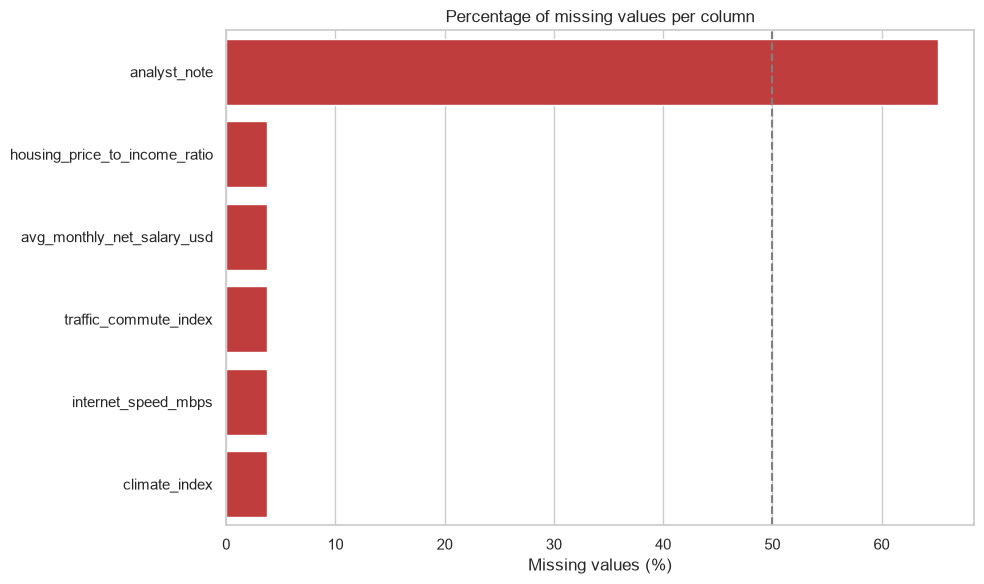

In [15]:
# Easy to understand this with a chart if there is any missing data.
# NONE in this case.

fig, ax = plt.subplots(figsize=(10, 6))

# Only plot the columns that have at least one missing value
missing_to_plot = missing[missing["pct_missing"] > 0]

sns.barplot(data=missing_to_plot, x="pct_missing", y=missing_to_plot.index, color="tab:red", ax=ax)
ax.axvline(50, color="grey", linestyle="--")   # reference line at 50%
ax.set_title("Percentage of missing values per column")
ax.set_xlabel("Missing values (%)")
ax.set_ylabel("")
plt.tight_layout()
save_fig("01_missing_values")
plt.show()

# Can decide what columns to drop based on this analysis.

In [17]:
#column removal for missing data
columns_to_drop = ["analyst_note",
                   "data_source_pattern"]

df_clean = df_clean.drop(columns=columns_to_drop, errors="ignore")

print(
    f"Remaining columns ({df_clean.shape[1]}): "
    f"{df_clean.columns.tolist()}"
)

Remaining columns (24): ['city_id', 'city', 'country', 'region', 'subregion', 'development_tier', 'population_millions', 'currency_code', 'survey_date', 'cost_of_living_index', 'rent_index', 'groceries_index', 'restaurant_price_index', 'local_purchasing_power_index', 'avg_monthly_net_salary_usd', 'housing_price_to_income_ratio', 'health_care_index', 'safety_index', 'pollution_index', 'traffic_commute_index', 'climate_index', 'internet_speed_mbps', 'quality_of_life_index', 'qol_category']


In [18]:
# Check new dataset scope.

print(f"Reduced data scope: {len(df_clean)}")
df_clean.head()

Reduced data scope: 296


,city_id,city,country,region,subregion,development_tier,population_millions,currency_code,survey_date,cost_of_living_index,rent_index,groceries_index,restaurant_price_index,local_purchasing_power_index,avg_monthly_net_salary_usd,housing_price_to_income_ratio,health_care_index,safety_index,pollution_index,traffic_commute_index,climate_index,internet_speed_mbps,quality_of_life_index,qol_category
0,112,Abidjan,Cote d'Ivoire,Africa,Western Africa,4,4.89,XOF,2023-06-15,43.29,24.06,43.18,46.49,38.45,"1,650.87",18.48,29.59,49.52,86.13,61.74,85.79,38.10,42.92,Medium
1,112,Abidjan,Cote d'Ivoire,Africa,Western Africa,4,4.89,XOF,2024-06-15,51.53,26.11,47.59,46.68,43.25,"1,826.78",20.84,22.86,49.85,86.33,63.21,63.07,47.30,32.57,Low
2,76,Abu Dhabi,United Arab Emirates,Asia,Western Asia,1,3.22,AED,2023-06-15,100.39,61.19,86.04,64.62,111.37,"6,040.30",8.82,96.34,94.67,38.15,32.22,83.63,168.40,82.84,Very High
3,76,Abu Dhabi,United Arab Emirates,Asia,Western Asia,1,3.22,AED,2024-06-15,95.65,78.33,98.88,84.45,109.32,"6,363.54",10.11,89.47,56.12,28.94,29.20,31.57,NaN,59.92,High
4,99,Abuja,Nigeria,Africa,Western Africa,4,2.64,NGN,2023-06-15,46.82,32.79,29.90,39.25,49.86,"2,186.81",18.82,38.37,47.52,78.13,65.04,58.49,81.90,38.86,Medium


In [19]:
# check the info and data types of each column in the cleaned table
df_clean.info()
df_clean.describe(include="all").T

<class 'pandas.DataFrame'>
RangeIndex: 296 entries, 0 to 295
Data columns (total 24 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   city_id                        296 non-null    int64  
 1   city                           296 non-null    str    
 2   country                        296 non-null    str    
 3   region                         296 non-null    str    
 4   subregion                      296 non-null    str    
 5   development_tier               296 non-null    int64  
 6   population_millions            296 non-null    float64
 7   currency_code                  296 non-null    str    
 8   survey_date                    296 non-null    str    
 9   cost_of_living_index           296 non-null    float64
 10  rent_index                     296 non-null    float64
 11  groceries_index                296 non-null    float64
 12  restaurant_price_index         296 non-null    float64
 13  l

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
city_id,296.00,NaN,NaN,NaN,74.50,42.80,1.00,37.75,74.50,111.25,148.00
city,296,148,Abidjan,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,296,92,United States,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,296,5,Europe,92,NaN,NaN,NaN,NaN,NaN,NaN,NaN
subregion,296,17,Northern America,34,NaN,NaN,NaN,NaN,NaN,NaN,NaN
development_tier,296.00,NaN,NaN,NaN,2.26,1.13,1.00,1.00,2.00,3.00,4.00
population_millions,296.00,NaN,NaN,NaN,5.10,6.00,0.31,1.94,3.13,5.60,38.00
currency_code,296,75,EUR,48,NaN,NaN,NaN,NaN,NaN,NaN,NaN
survey_date,296,2,2023-06-15,148,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cost_of_living_index,296.00,NaN,NaN,NaN,75.16,22.31,23.54,58.85,76.97,94.70,113.29


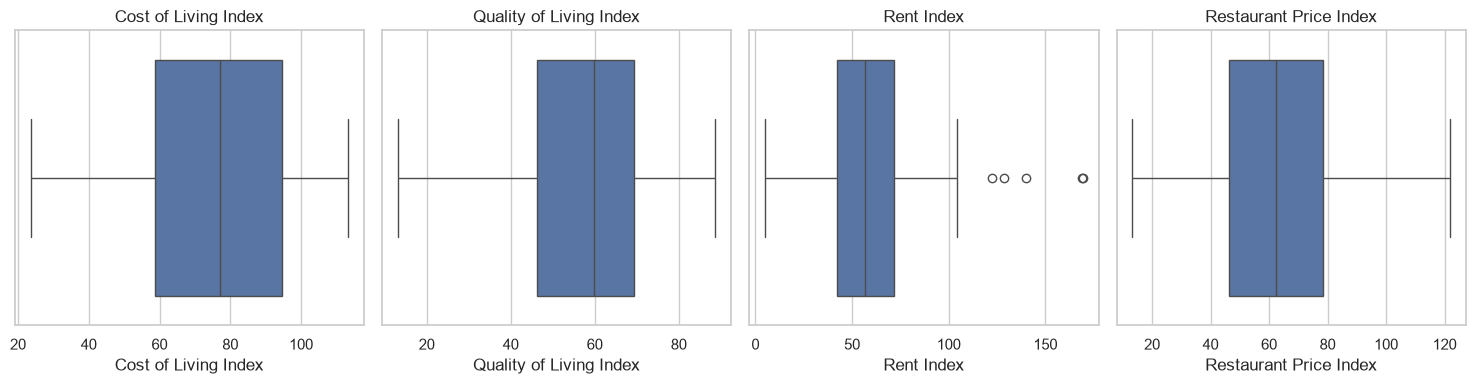

In [24]:
# inspect the distribution of the remaining numeric columns using boxplots to identify outliers and understand the spread of the data.

# Box -> Middle 50% of values
# Line inside the box ->	Median—the middle value
# Whiskers->Range defined by the boxplot rule
# Dots beyond the whiskers -> Potential outliers to investigate

fig, axes = plt.subplots(1, 4, figsize=(15, 4))

sns.boxplot(x=df_clean["cost_of_living_index"], ax=axes[0])
axes[0].set_title("Cost of Living Index")
axes[0].set_xlabel("Cost of Living Index")

sns.boxplot(x=df_clean["quality_of_life_index"], ax=axes[1])
axes[1].set_title("Quality of Living Index")
axes[1].set_xlabel("Quality of Living Index")

sns.boxplot(x=df_clean["rent_index"], ax=axes[2])
axes[2].set_title("Rent Index")
axes[2].set_xlabel("Rent Index")

sns.boxplot(x=df_clean["restaurant_price_index"], ax=axes[3])
axes[3].set_title("Restaurant Price Index")
axes[3].set_xlabel("Restaurant Price Index")

plt.tight_layout()
plt.savefig(FIG_DIR / "01_BoxPlot.png") #save fig
plt.show()
